Below we implement the cost function and ZO-GD method

In [1]:
import numpy as np
import time
import matplotlib.pyplot as plt

# ──────────────────────────────────────────────────────
# Problem setup: f(x) = x^T A x, A ∈ R^{1000×1000} SPD
# ──────────────────────────────────────────────────────
# np.random.seed(42)
n = 1000

# A = Q diag(λ) Q^T, λ_i ∈ [1, 100]  →  condition number ≈ 100
Q, _ = np.linalg.qr(np.random.randn(n, n))
eigvals = np.linspace(1.0, 100.0, n)
A = Q @ np.diag(eigvals) @ Q.T
A = 0.5 * (A + A.T)

x_star = np.zeros(n)
def f(x):
    return x @ A @ x

def grad_f(x):
    return 2.0 * A @ x

# ──────────────────────────────────────────────────────
# ZO gradient estimator (one-point, Gaussian smoothing)
# n-D extension: g_est = [(f(x+μu) - f(x)) / μ] * u
# ──────────────────────────────────────────────────────
def zo_gradient(x, mu=0.01,t=1):
    g_est = np.zeros_like(x)
    for i in range(t):  # try multiple times to avoid zero direction
        u = np.random.randn(n)
        f_perturbed = f(x + mu * u)
        f_current   = f(x)
        g_est += ((f_perturbed - f_current) / mu) * u
    return g_est/t

# ──────────────────────────────────────────────────────
# Gradient descent
# ──────────────────────────────────────────────────────
def run_gd(x0, lr, max_iter):
    x = x0.copy()
    fvals, dists, times = [], [], []
    t0 = time.perf_counter()
    for _ in range(max_iter):
        fvals.append(f(x))
        dists.append(np.linalg.norm(x - x_star))
        times.append(time.perf_counter() - t0)
        x = x - lr * grad_f(x)
    return np.array(fvals), np.array(dists), np.array(times)

# ──────────────────────────────────────────────────────
# ZO gradient descent
# ──────────────────────────────────────────────────────
def run_zo_gd(x0, lr, mu, max_iter,t=1):
    # np.random.seed(seed)
    x = x0.copy()
    fvals, dists, times = [], [], []
    t0 = time.perf_counter()
    for _ in range(max_iter):
        fvals.append(f(x))
        dists.append(np.linalg.norm(x - x_star))
        times.append(time.perf_counter() - t0)
        x = x - lr * zo_gradient(x, mu=mu, t=t)
    return np.array(fvals), np.array(dists), np.array(times)

# ──────────────────────────────────────────────────────
# Parameters
# ──────────────────────────────────────────────────────
max_iter_gd = 1000
max_iter_zo = 1000

L = 2.0 * eigvals[-1]       # Lipschitz constant of gradient
lr_gd = 1e-3           
lr_zo = lr_gd     
mu_zo = 1e-9
t = 64
x0 = np.random.randn(n)*0.1

print("Running exact GD ...")
gd_f, gd_d, gd_t = run_gd(x0, lr_gd, max_iter_gd)

print("Running ZO-GD ...")
zo_f, zo_d, zo_t = run_zo_gd(x0, lr_zo, mu_zo, max_iter_zo, t=t)

print(f"GD  final: f = {gd_f[-1]:.4e}, dist = {gd_d[-1]:.4e}, time = {gd_t[-1]:.3f}s")
print(f"ZO  final: f = {zo_f[-1]:.4e}, dist = {zo_d[-1]:.4e}, time = {zo_t[-1]:.3f}s")



/home/amirali/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Running exact GD ...
Running ZO-GD ...
GD  final: f = 8.0902e-04, dist = 2.5283e-02, time = 2.841s
ZO  final: f = 6.1677e-03, dist = 6.1049e-02, time = 44.025s


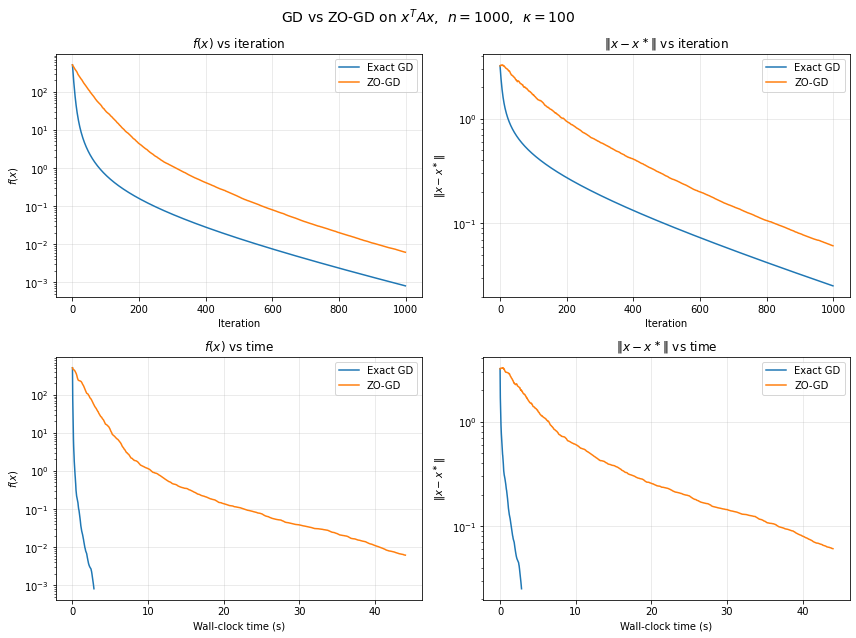

In [3]:
# ──────────────────────────────────────────────────────
# Plot
# ──────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

gd_iters = np.arange(max_iter_gd)
zo_iters = np.arange(max_iter_zo)

# f(x) vs iteration
axes[0, 0].semilogy(gd_iters, gd_f, label="Exact GD")
axes[0, 0].semilogy(zo_iters, zo_f, label="ZO-GD")
axes[0, 0].set_xlabel("Iteration")
axes[0, 0].set_ylabel(r"$f(x)$")
axes[0, 0].set_title(r"$f(x)$ vs iteration")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# ||x - x*|| vs iteration
axes[0, 1].semilogy(gd_iters, gd_d, label="Exact GD")
axes[0, 1].semilogy(zo_iters, zo_d, label="ZO-GD")
axes[0, 1].set_xlabel("Iteration")
axes[0, 1].set_ylabel(r"$\|x - x^\ast\|$")
axes[0, 1].set_title(r"$\|x - x^\ast\|$ vs iteration")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# f(x) vs time
axes[1, 0].semilogy(gd_t, gd_f, label="Exact GD")
axes[1, 0].semilogy(zo_t, zo_f, label="ZO-GD")
axes[1, 0].set_xlabel("Wall-clock time (s)")
axes[1, 0].set_ylabel(r"$f(x)$")
axes[1, 0].set_title(r"$f(x)$ vs time")
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# ||x - x*|| vs time
axes[1, 1].semilogy(gd_t, gd_d, label="Exact GD")
axes[1, 1].semilogy(zo_t, zo_d, label="ZO-GD")
axes[1, 1].set_xlabel("Wall-clock time (s)")
axes[1, 1].set_ylabel(r"$\|x - x^\ast\|$")
axes[1, 1].set_title(r"$\|x - x^\ast\|$ vs time")
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

fig.suptitle(
    rf"GD vs ZO-GD on $x^T A x$,  $n={n}$,  $\kappa={eigvals[-1]/eigvals[0]:.0f}$",
    fontsize=14,
)
fig.tight_layout()
plt.savefig("gd_vs_zo.png", dpi=150)
plt.show()

In [2]:
np.linalg.norm(grad_f(x0))**2 * n

135584173.65689182

Below we test different step-sizes with fixed smoothing parameter and number of directions.

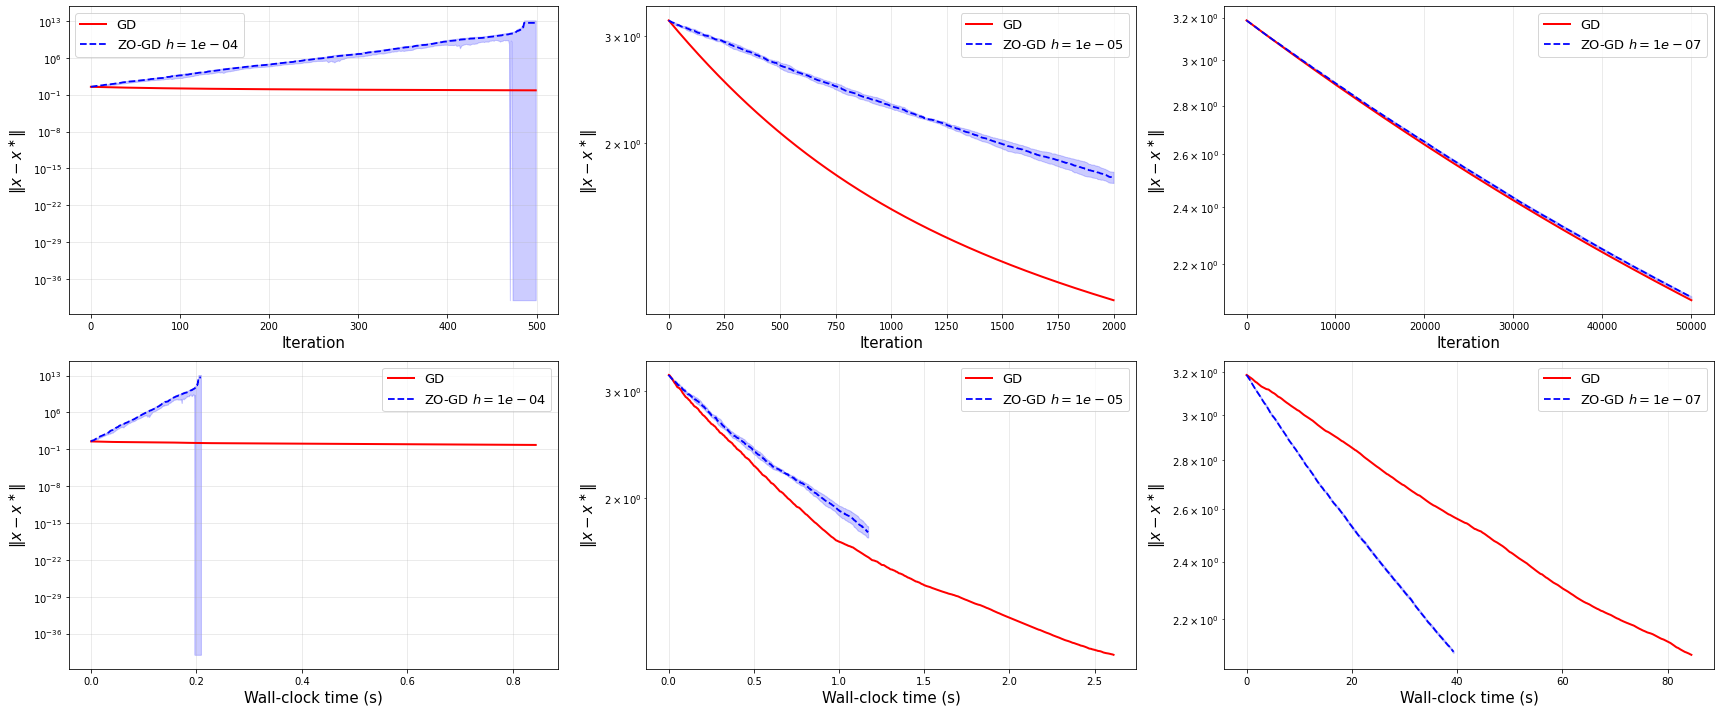

In [6]:
#### Different lr_gd (= lr_zo), fixed t and mu
mu_fixed = 1e-5
t_fixed  = 1
n_runs   = 5

# Each entry: (lr, max_iter) — step size with its own iteration budget
lr_config = [
    (1e-4, 500),
    (1e-5, 2000),
    (1e-7, 50000),
]

fig, axes = plt.subplots(2, len(lr_config), figsize=(8 * len(lr_config), 10))

for row, (lr, max_iter) in enumerate(lr_config):
    lbl = rf"$h={lr:.0e}$"
    iters = np.arange(max_iter)
    ax_it, ax_tm = axes[0, row], axes[1, row]

    # GD (deterministic)
    _, gd_d, gd_t = run_gd(x0, lr, max_iter)
    ax_it.semilogy(iters, gd_d, 'r-',  linewidth=2.0, label="GD")
    ax_tm.semilogy(gd_t,  gd_d, 'r-',  linewidth=2.0, label="GD")

    # ZO-GD averaged over n_runs
    runs = [run_zo_gd(x0, lr, mu_fixed, max_iter, t=t_fixed) for _ in range(n_runs)]
    zo_d_mat  = np.array([r[1] for r in runs])   # shape (n_runs, max_iter)
    zo_t_mat  = np.array([r[2] for r in runs])   # shape (n_runs, max_iter)

    zo_d_avg  = zo_d_mat.mean(axis=0)
    zo_d_std  = zo_d_mat.std(axis=0)
    zo_t_avg  = zo_t_mat.mean(axis=0)

    ax_it.semilogy(iters, zo_d_avg, 'b--', linewidth=1.8, label=f"ZO-GD {lbl}")
    ax_it.fill_between(iters,
                       np.maximum(zo_d_avg - zo_d_std, 1e-40),  # avoid log(0)
                       zo_d_avg + zo_d_std,
                       alpha=0.2, color='b')

    ax_tm.semilogy(zo_t_avg, zo_d_avg, 'b--', linewidth=1.8, label=f"ZO-GD {lbl}")
    ax_tm.fill_between(zo_t_avg,
                       np.maximum(zo_d_avg - zo_d_std, 1e-40),
                       zo_d_avg + zo_d_std,
                       alpha=0.2, color='b')

    for ax, xlabel in zip([ax_it, ax_tm], ["Iteration", "Wall-clock time (s)"]):
        ax.set_xlabel(xlabel, fontsize=15)
        ax.set_ylabel(r"$\|x - x^\ast\|$", fontsize=15)
        ax.legend(fontsize=13)
        ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.savefig("param_lr.pdf", dpi=300, format='pdf', bbox_inches='tight')
plt.show()


Below we test different smoothing parameters with fixed step size and number of directions.

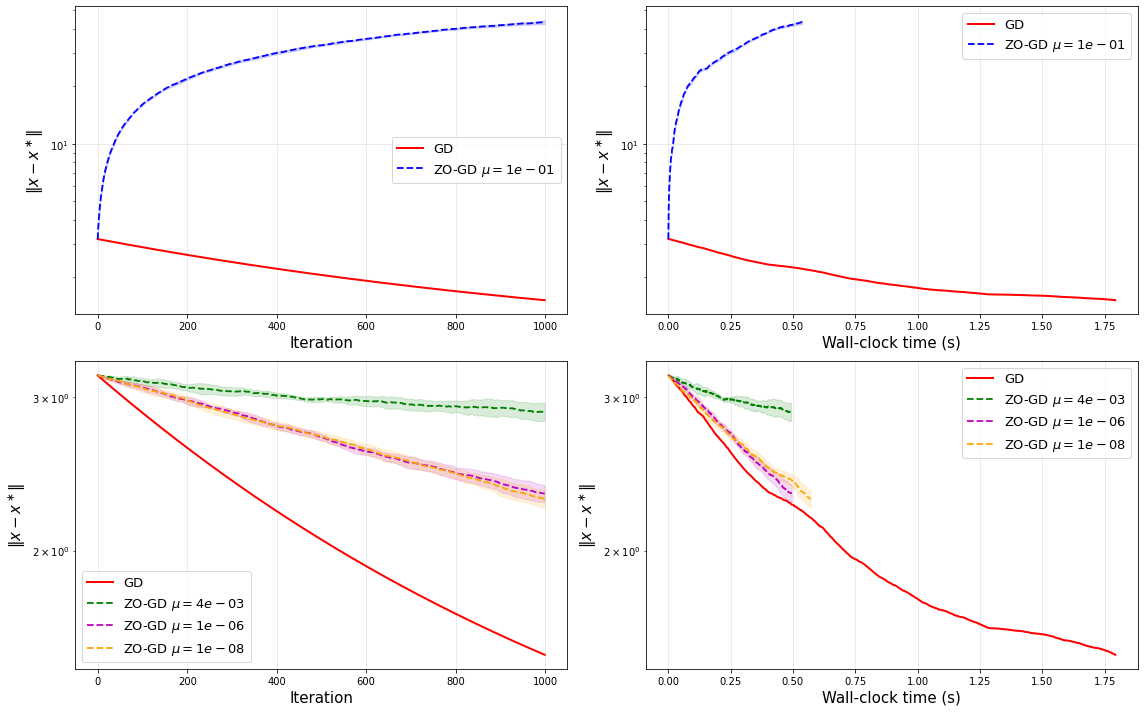

In [51]:
#### Different mu, fixed t and lr
lr_fixed = 1e-5
t_fixed  = 1
n_runs   = 5
max_iter = 1000

mu_large  = 1e-1                        # row 1: diverging case
mu_others = [4e-3, 1e-6, 1e-8]         # row 2: converging cases
colors    = ['g', 'm', 'orange']
iters     = np.arange(max_iter)

# GD is mu-independent — run once
_, gd_d, gd_t = run_gd(x0, lr_fixed, max_iter)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# ── Row 1: GD vs ZO-GD with largest mu (diverging) ──
ax_it, ax_tm = axes[0, 0], axes[0, 1]
ax_it.semilogy(iters, gd_d, 'r-', linewidth=2.0, label="GD")
ax_tm.semilogy(gd_t,  gd_d, 'r-', linewidth=2.0, label="GD")

lbl = rf"$\mu={mu_large:.0e}$"
runs = [run_zo_gd(x0, lr_fixed, mu_large, max_iter, t=t_fixed) for _ in range(n_runs)]
zo_d_mat = np.array([r[1] for r in runs])
zo_t_mat = np.array([r[2] for r in runs])
zo_d_avg = zo_d_mat.mean(axis=0)
zo_d_std = zo_d_mat.std(axis=0)
zo_t_avg = zo_t_mat.mean(axis=0)

ax_it.semilogy(iters, zo_d_avg, 'b--', linewidth=1.8, label=f"ZO-GD {lbl}")
ax_it.fill_between(iters,
                   np.maximum(zo_d_avg - zo_d_std, 1e-40),
                   zo_d_avg + zo_d_std, alpha=0.15, color='b')
ax_tm.semilogy(zo_t_avg, zo_d_avg, 'b--', linewidth=1.8, label=f"ZO-GD {lbl}")
ax_tm.fill_between(zo_t_avg,
                   np.maximum(zo_d_avg - zo_d_std, 1e-40),
                   zo_d_avg + zo_d_std, alpha=0.15, color='b')

# ── Row 2: GD vs ZO-GD with smaller mu values ──
ax_it, ax_tm = axes[1, 0], axes[1, 1]
ax_it.semilogy(iters, gd_d, 'r-', linewidth=2.0, label="GD")
ax_tm.semilogy(gd_t,  gd_d, 'r-', linewidth=2.0, label="GD")

for mu, color in zip(mu_others, colors):
    lbl = rf"$\mu={mu:.0e}$"
    runs = [run_zo_gd(x0, lr_fixed, mu, max_iter, t=t_fixed) for _ in range(n_runs)]
    zo_d_mat = np.array([r[1] for r in runs])
    zo_t_mat = np.array([r[2] for r in runs])
    zo_d_avg = zo_d_mat.mean(axis=0)
    zo_d_std = zo_d_mat.std(axis=0)
    zo_t_avg = zo_t_mat.mean(axis=0)

    ax_it.semilogy(iters, zo_d_avg, '--', color=color, linewidth=1.8, label=f"ZO-GD {lbl}")
    ax_it.fill_between(iters,
                       np.maximum(zo_d_avg - zo_d_std, 1e-40),
                       zo_d_avg + zo_d_std, alpha=0.15, color=color)
    ax_tm.semilogy(zo_t_avg, zo_d_avg, '--', color=color, linewidth=1.8, label=f"ZO-GD {lbl}")
    ax_tm.fill_between(zo_t_avg,
                       np.maximum(zo_d_avg - zo_d_std, 1e-40),
                       zo_d_avg + zo_d_std, alpha=0.15, color=color)

for ax, xlabel in zip(axes.flat, ["Iteration", "Wall-clock time (s)"] * 2):
    ax.set_xlabel(xlabel, fontsize=15)
    ax.set_ylabel(r"$\|x - x^\ast\|$", fontsize=15)
    ax.legend(fontsize=13)
    ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.savefig("param_mu.pdf", dpi=300, format='pdf', bbox_inches='tight')
plt.show()

Below we test different numbers of directions with fixed step size and smoothing parameter.

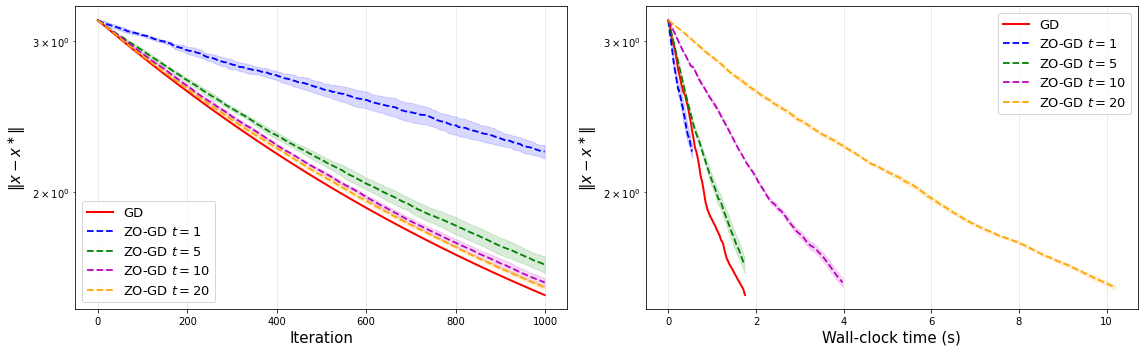

In [52]:
#### Different t (query budget per step), fixed mu and lr
lr_fixed = 1e-5
mu_fixed = 1e-5
n_runs   = 5
max_iter = 1000

t_values = [1, 5, 10, 20]
colors   = ['b', 'g', 'm', 'orange']
iters    = np.arange(max_iter)

# GD is t-independent — run once
_, gd_d, gd_t = run_gd(x0, lr_fixed, max_iter)

fig, (ax_it, ax_tm) = plt.subplots(1, 2, figsize=(16, 5))

ax_it.semilogy(iters, gd_d, 'r-', linewidth=2.0, label="GD")
ax_tm.semilogy(gd_t,  gd_d, 'r-', linewidth=2.0, label="GD")

for t_val, color in zip(t_values, colors):
    lbl = rf"$t={t_val}$"

    runs = [run_zo_gd(x0, lr_fixed, mu_fixed, max_iter, t=t_val) for _ in range(n_runs)]
    zo_d_mat = np.array([r[1] for r in runs])
    zo_t_mat = np.array([r[2] for r in runs])

    zo_d_avg = zo_d_mat.mean(axis=0)
    zo_d_std = zo_d_mat.std(axis=0)
    zo_t_avg = zo_t_mat.mean(axis=0)

    ax_it.semilogy(iters, zo_d_avg, '--', color=color, linewidth=1.8, label=f"ZO-GD {lbl}")
    ax_it.fill_between(iters,
                       np.maximum(zo_d_avg - zo_d_std, 1e-40),
                       zo_d_avg + zo_d_std, alpha=0.15, color=color)

    ax_tm.semilogy(zo_t_avg, zo_d_avg, '--', color=color, linewidth=1.8, label=f"ZO-GD {lbl}")
    ax_tm.fill_between(zo_t_avg,
                       np.maximum(zo_d_avg - zo_d_std, 1e-40),
                       zo_d_avg + zo_d_std, alpha=0.15, color=color)

for ax, xlabel in zip([ax_it, ax_tm], ["Iteration", "Wall-clock time (s)"]):
    ax.set_xlabel(xlabel, fontsize=15)
    ax.set_ylabel(r"$\|x - x^\ast\|$", fontsize=15)
    ax.legend(fontsize=13)
    ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.savefig("param_t.pdf", dpi=300, format='pdf', bbox_inches='tight')
plt.show()


Below we test the parameter sets used in parameter compensation section of the paper (compensating for the cases , where ZO-GD diverged above).

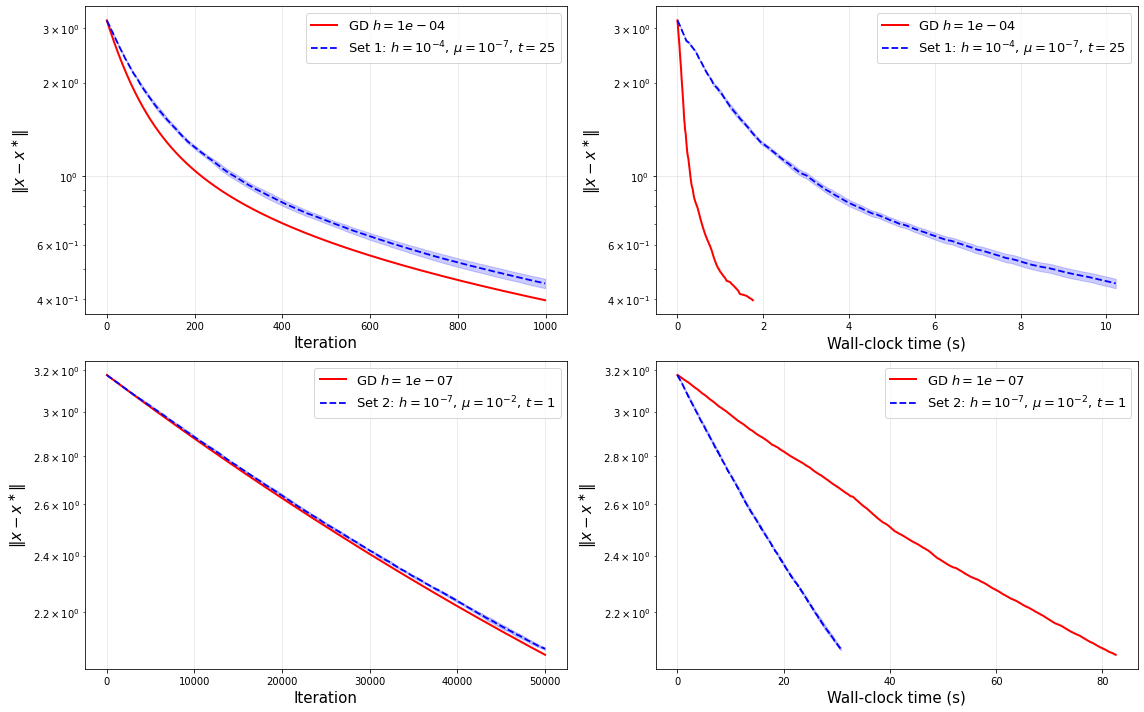

In [56]:
#### Compare 2 parameter sets (mu, lr, t) — 5 runs of ZO-GD, averaged
n_runs   = 5
# max_iter = 1000


param_sets = [
    {"mu": 1e-7, "lr": 1e-4, "t": 25, "N":1000, "label": r"Set 1: $h=10^{-4},\,\mu=10^{-7},\,t=25$"},
    {"mu": 1e-2, "lr": 1e-7, "t": 1, "N":50000, "label": r"Set 2: $h=10^{-7},\,\mu=10^{-2},\,t=1$"},
]

colors_zo = ['b', 'b']
colors_gd = ['r', 'r']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
# fig.suptitle("ZO-GD: comparison of 2 parameter sets (5-run average)", fontsize=14)

for i, ps in enumerate(param_sets):
    ax_it, ax_tm = axes[i, 0], axes[i, 1]
    iters    = np.arange(ps["N"])
    # Exact GD reference with matching lr
    _, gd_d, gd_t = run_gd(x0, ps["lr"], ps["N"])
    ax_it.semilogy(iters, gd_d, color=colors_gd[i], linestyle='-',
                   linewidth=2.0, label=rf"GD $h={ps['lr']:.0e}$")
    ax_tm.semilogy(gd_t,  gd_d, color=colors_gd[i], linestyle='-',
                   linewidth=2.0, label=rf"GD $h={ps['lr']:.0e}$")

    # ZO-GD averaged over n_runs
    runs = [run_zo_gd(x0, ps["lr"], ps["mu"], ps["N"], t=ps["t"])
            for _ in range(n_runs)]
    zo_d_mat  = np.array([r[1] for r in runs])   # shape (n_runs, max_iter)
    zo_t_mat  = np.array([r[2] for r in runs])   # shape (n_runs, max_iter)

    zo_d_avg  = zo_d_mat.mean(axis=0)
    zo_d_std  = zo_d_mat.std(axis=0)
    zo_t_avg  = zo_t_mat.mean(axis=0)

    ax_it.semilogy(iters, zo_d_avg, color=colors_zo[i], linestyle='--',
                   linewidth=1.8, label=ps["label"])
    ax_it.fill_between(iters,
                       np.maximum(zo_d_avg - zo_d_std, 1e-40),  # avoid log(0)
                       zo_d_avg + zo_d_std,
                       alpha=0.2, color='b')

    ax_tm.semilogy(zo_t_avg, zo_d_avg, color=colors_zo[i], linestyle='--',
                   linewidth=1.8, label=ps["label"])
    ax_tm.fill_between(zo_t_avg,
                       np.maximum(zo_d_avg - zo_d_std, 1e-40),
                       zo_d_avg + zo_d_std,
                       alpha=0.2, color='b')


    set_title = f"Parameter Set {i+1}"
    # ax_it.set_title(rf"{set_title}: $\|x - x^\ast\|$ vs iteration")
    # ax_tm.set_title(rf"{set_title}: $\|x - x^\ast\|$ vs wall-clock time")

    for ax, xlabel in zip([ax_it, ax_tm], ["Iteration", "Wall-clock time (s)"]):
        ax.set_xlabel(xlabel, fontsize=15)
        ax.set_ylabel(r"$\|x - x^\ast\|$", fontsize=15)
        ax.legend(fontsize=13)
        ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.savefig("param_sets_comparison.pdf", dpi=300, format='pdf', bbox_inches='tight')
plt.show()


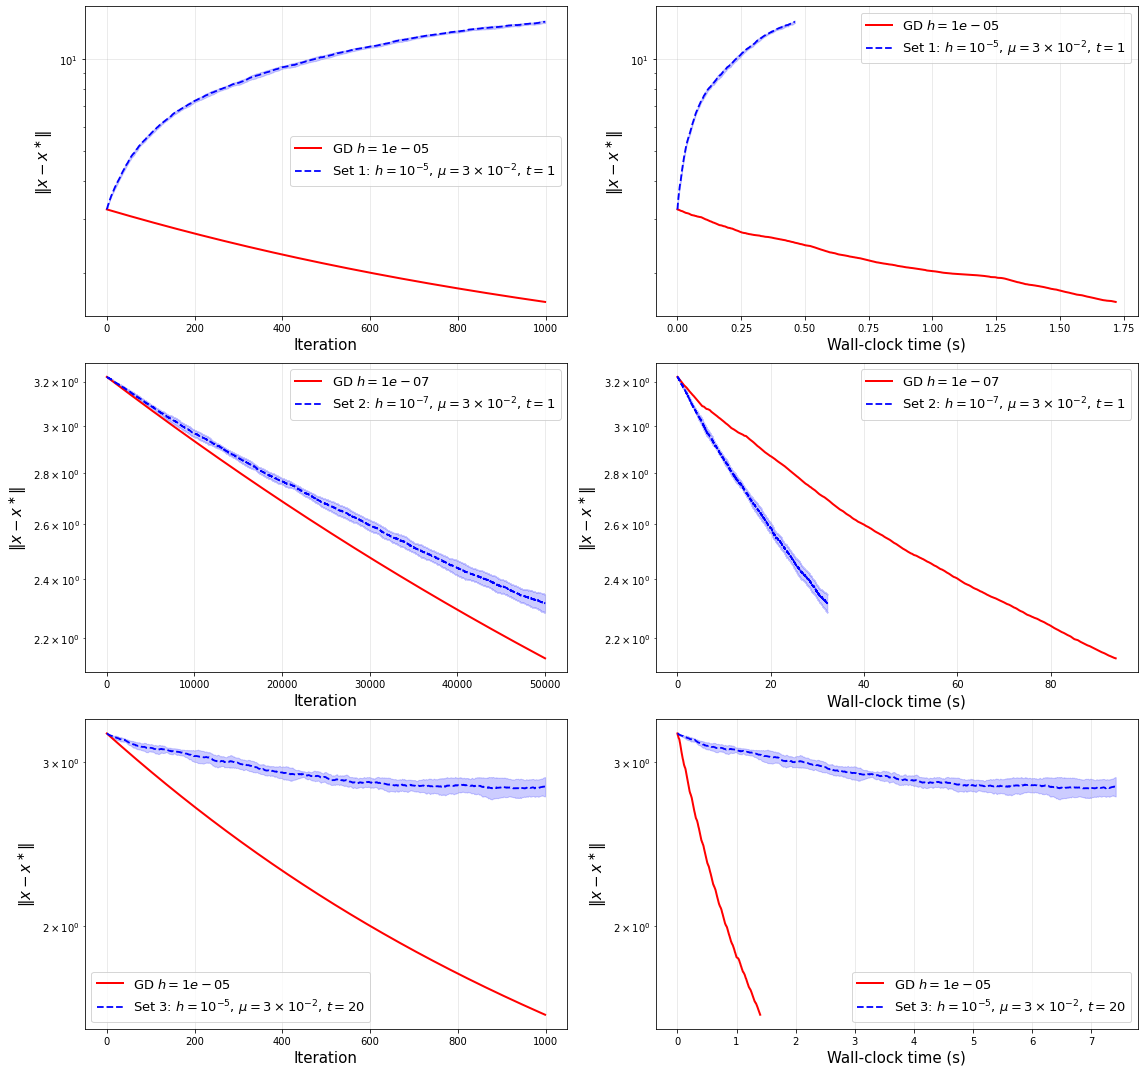

In [66]:
#### Compare 2 parameter sets (mu, lr, t) — 5 runs of ZO-GD, averaged
n_runs   = 5
max_iter = 1000


param_sets = [
    {"mu": 3e-2, "lr": 1e-5, "t": 1, "N":1000, "label": r"Set 1: $h=10^{-5},\,\mu=3\times10^{-2},\,t=1$"},
    {"mu": 3e-2, "lr": 1e-7, "t": 1, "N":50000, "label": r"Set 2: $h=10^{-7},\,\mu=3\times10^{-2},\,t=1$"},
    {"mu": 3e-2, "lr": 1e-5, "t": 20, "N":1000, "label": r"Set 3: $h=10^{-5},\,\mu=3\times10^{-2},\,t=20$"},
]

colors_zo = ['b', 'b', 'b']
colors_gd = ['r', 'r', 'r']

fig, axes = plt.subplots(3, 2, figsize=(16, 15))
# fig.suptitle("ZO-GD: comparison of 2 parameter sets (5-run average)", fontsize=14)

for i, ps in enumerate(param_sets):
    ax_it, ax_tm = axes[i, 0], axes[i, 1]
    iters    = np.arange(ps["N"])
    # Exact GD reference with matching lr
    _, gd_d, gd_t = run_gd(x0, ps["lr"], ps["N"])
    ax_it.semilogy(iters, gd_d, color=colors_gd[i], linestyle='-',
                   linewidth=2.0, label=rf"GD $h={ps['lr']:.0e}$")
    ax_tm.semilogy(gd_t,  gd_d, color=colors_gd[i], linestyle='-',
                   linewidth=2.0, label=rf"GD $h={ps['lr']:.0e}$")

    # ZO-GD averaged over n_runs
    runs = [run_zo_gd(x0, ps["lr"], ps["mu"], ps["N"], t=ps["t"])
            for _ in range(n_runs)]
    zo_d_all = np.array([r[1] for r in runs])
    zo_t_all = np.array([r[2] for r in runs])
    zo_d_avg = zo_d_all.mean(axis=0)
    zo_t_avg = zo_t_all.mean(axis=0)
    zo_d_std = zo_d_all.std(axis=0)

    ax_it.semilogy(iters, zo_d_avg, color=colors_zo[i], linestyle='--',
                   linewidth=1.8, label=ps["label"])
    ax_it.fill_between(iters,
                        np.maximum(zo_d_avg - zo_d_std, 1e-40),
                        zo_d_avg + zo_d_std,
                        color=colors_zo[i], alpha=0.2)

    ax_tm.semilogy(zo_t_avg, zo_d_avg, color=colors_zo[i], linestyle='--',
                   linewidth=1.8, label=ps["label"])
    
    ax_tm.fill_between(zo_t_avg,
                        np.maximum(zo_d_avg - zo_d_std, 1e-40),
                        zo_d_avg + zo_d_std,
                        color=colors_zo[i], alpha=0.2)

    set_title = f"Parameter Set {i+1}"
    # ax_it.set_title(rf"{set_title}: $\|x - x^\ast\|$ vs iteration")
    # ax_tm.set_title(rf"{set_title}: $\|x - x^\ast\|$ vs wall-clock time")

    for ax, xlabel in zip([ax_it, ax_tm], ["Iteration", "Wall-clock time (s)"]):
        ax.set_xlabel(xlabel, fontsize=15)
        ax.set_ylabel(r"$\|x - x^\ast\|$", fontsize=15)
        ax.legend(fontsize=13)
        ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.savefig("param_sets_comparison2.pdf", dpi=300, format='pdf', bbox_inches='tight')
plt.show()
